In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/Bhumika Chandan/Downloads/Dataset .csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
restaurant_counts = (
    df.groupby("Restaurant Name")["Restaurant ID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Restaurant Chains:")
display(restaurant_counts.head(10))

Top 10 Restaurant Chains:


Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: Restaurant ID, dtype: int64

In [4]:
restaurant_chains = restaurant_counts[
    restaurant_counts > 1
]

print("Total Restaurant Chains:", len(restaurant_chains))

display(restaurant_chains.head(10))

Total Restaurant Chains: 734


Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: Restaurant ID, dtype: int64

In [5]:
chain_analysis = (
    df.groupby("Restaurant Name")
    .agg(
        Outlet_Count=("Restaurant ID", "nunique"),
        Average_Rating=("Aggregate rating", "mean"),
        Total_Votes=("Votes", "sum")
    )
)

chain_analysis = chain_analysis[
    chain_analysis["Outlet_Count"] > 1
]

chain_analysis = chain_analysis.sort_values(
    by="Outlet_Count",
    ascending=False
)

display(chain_analysis.head(10))

,Outlet_Count,Average_Rating,Total_Votes
Restaurant Name,,,
Cafe Coffee Day,83,2.419277,2428
Domino's Pizza,79,2.740506,6643
Subway,63,2.907937,6124
Green Chick Chop,51,2.672549,964
McDonald's,48,3.339583,5291
Keventers,34,2.870588,1263
Pizza Hut,30,3.320000,4961
Giani,29,2.689655,854
Baskin Robbins,28,1.860714,428


In [6]:
popular_chains = chain_analysis.sort_values(
    by="Total_Votes",
    ascending=False
)

display(popular_chains.head(10))

,Outlet_Count,Average_Rating,Total_Votes
Restaurant Name,,,
Barbeque Nation,26,4.353846,28142
AB's - Absolute Barbecues,4,4.825000,13400
Big Chill,4,4.475000,10853
Farzi Cafe,6,4.366667,10098
Truffles,2,3.950000,9682
Chili's,5,4.580000,8156
Joey's Pizza,2,4.250000,7807
Big Yellow Door,3,4.266667,7511
Saravana Bhavan,3,4.133333,7238


In [7]:
highest_rated_chains = chain_analysis[
    chain_analysis["Outlet_Count"] >= 2
].sort_values(
    by="Average_Rating",
    ascending=False
)

display(highest_rated_chains.head(10))

,Outlet_Count,Average_Rating,Total_Votes
Restaurant Name,,,
Talaga Sampireun,3,4.900,5514
AB's Absolute Barbecues,2,4.850,3151
Silantro Fil-Mex,2,4.850,1364
AB's - Absolute Barbecues,4,4.825,13400
Naturals Ice Cream,2,4.800,3094
Gymkhana,2,4.700,328
The Cheesecake Factory,2,4.650,3010
Garota de Ipanema,2,4.600,59
Dishoom,2,4.600,1269


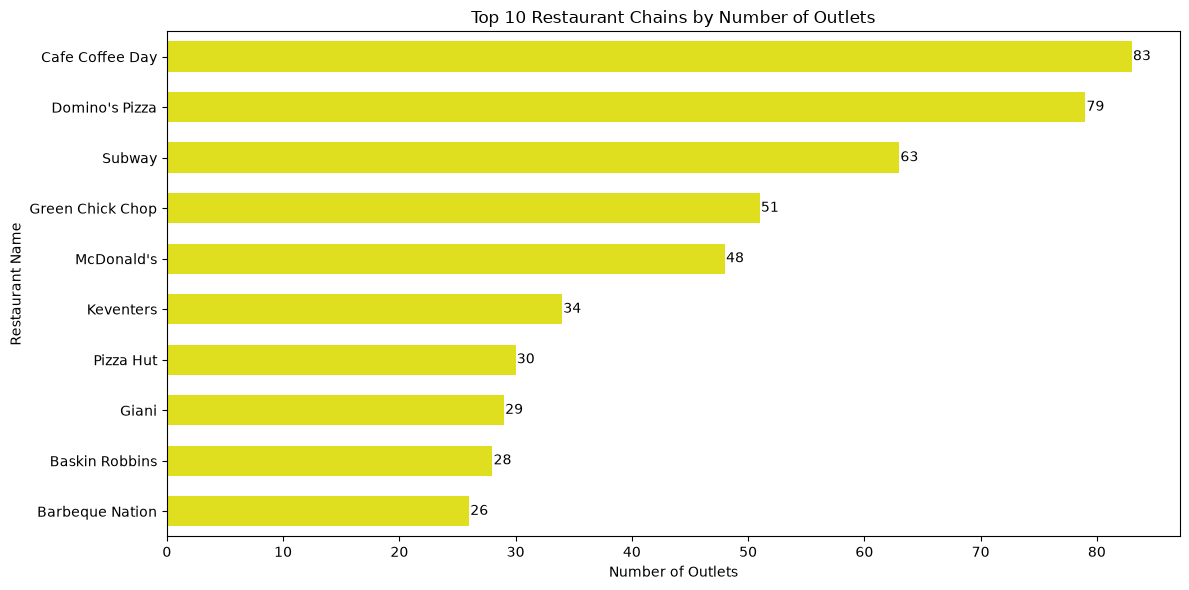

In [9]:
top_chains = chain_analysis.sort_values(
    by="Outlet_Count",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_chains["Outlet_Count"],
    y=top_chains.index,
    color="yellow",
    width=0.6
)

for i, value in enumerate(top_chains["Outlet_Count"]):
    ax.text(value + 0.1, i, str(value), va="center")

plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Number of Outlets")
plt.ylabel("Restaurant Name")

plt.tight_layout()
plt.savefig("Top_Restaurant_Chains.png", dpi=300)
plt.show()

In [11]:
chain_analysis.to_csv(
    "Restaurant_Chain_Analysis.csv"
)

popular_chains.head(10).to_csv(
    "Most_Popular_Restaurant_Chains.csv"
)

highest_rated_chains.head(10).to_csv(
    "Highest_Rated_Restaurant_Chains.csv"
)

print("Restaurant Chains Task Completed Successfully!")

Restaurant Chains Task Completed Successfully!
